# 📈 Sales Prediction Using Python
**Oasis Infobyte SIP · Data Science · Task 5**

**Objective:** Predict product sales from advertising spend on three channels (TV, Radio, Newspaper) and find which channel has the biggest impact on sales.

**Dataset:** `Advertising.csv`, 200 markets, with ad spend per channel (in thousands of dollars) and the resulting Sales (in thousands of units).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
import warnings; warnings.filterwarnings("ignore")

## 1. Load Data and EDA

In [2]:
df = pd.read_csv("Advertising.csv", index_col=0)
df.head()

,TV,Radio,Newspaper,Sales
1,230.1,37.8,69.2,22.1
2,44.5,39.3,45.1,10.4
3,17.2,45.9,69.3,9.3
4,151.5,41.3,58.5,18.5
5,180.8,10.8,58.4,12.9


In [3]:
print("Shape:", df.shape)
print("\nData types:\n", df.dtypes)
print("\nNull values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Shape: (200, 4)

Data types:
 TV           float64
Radio        float64
Newspaper    float64
Sales        float64
dtype: object

Null values:
 TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

Duplicate rows: 0


In [4]:
df.describe().round(2)

,TV,Radio,Newspaper,Sales
count,200.00,200.00,200.00,200.00
mean,147.04,23.26,30.55,14.02
std,85.85,14.85,21.78,5.22
min,0.70,0.00,0.30,1.60
25%,74.38,9.98,12.75,10.38
50%,149.75,22.90,25.75,12.90
75%,218.82,36.52,45.10,17.40
max,296.40,49.60,114.00,27.00


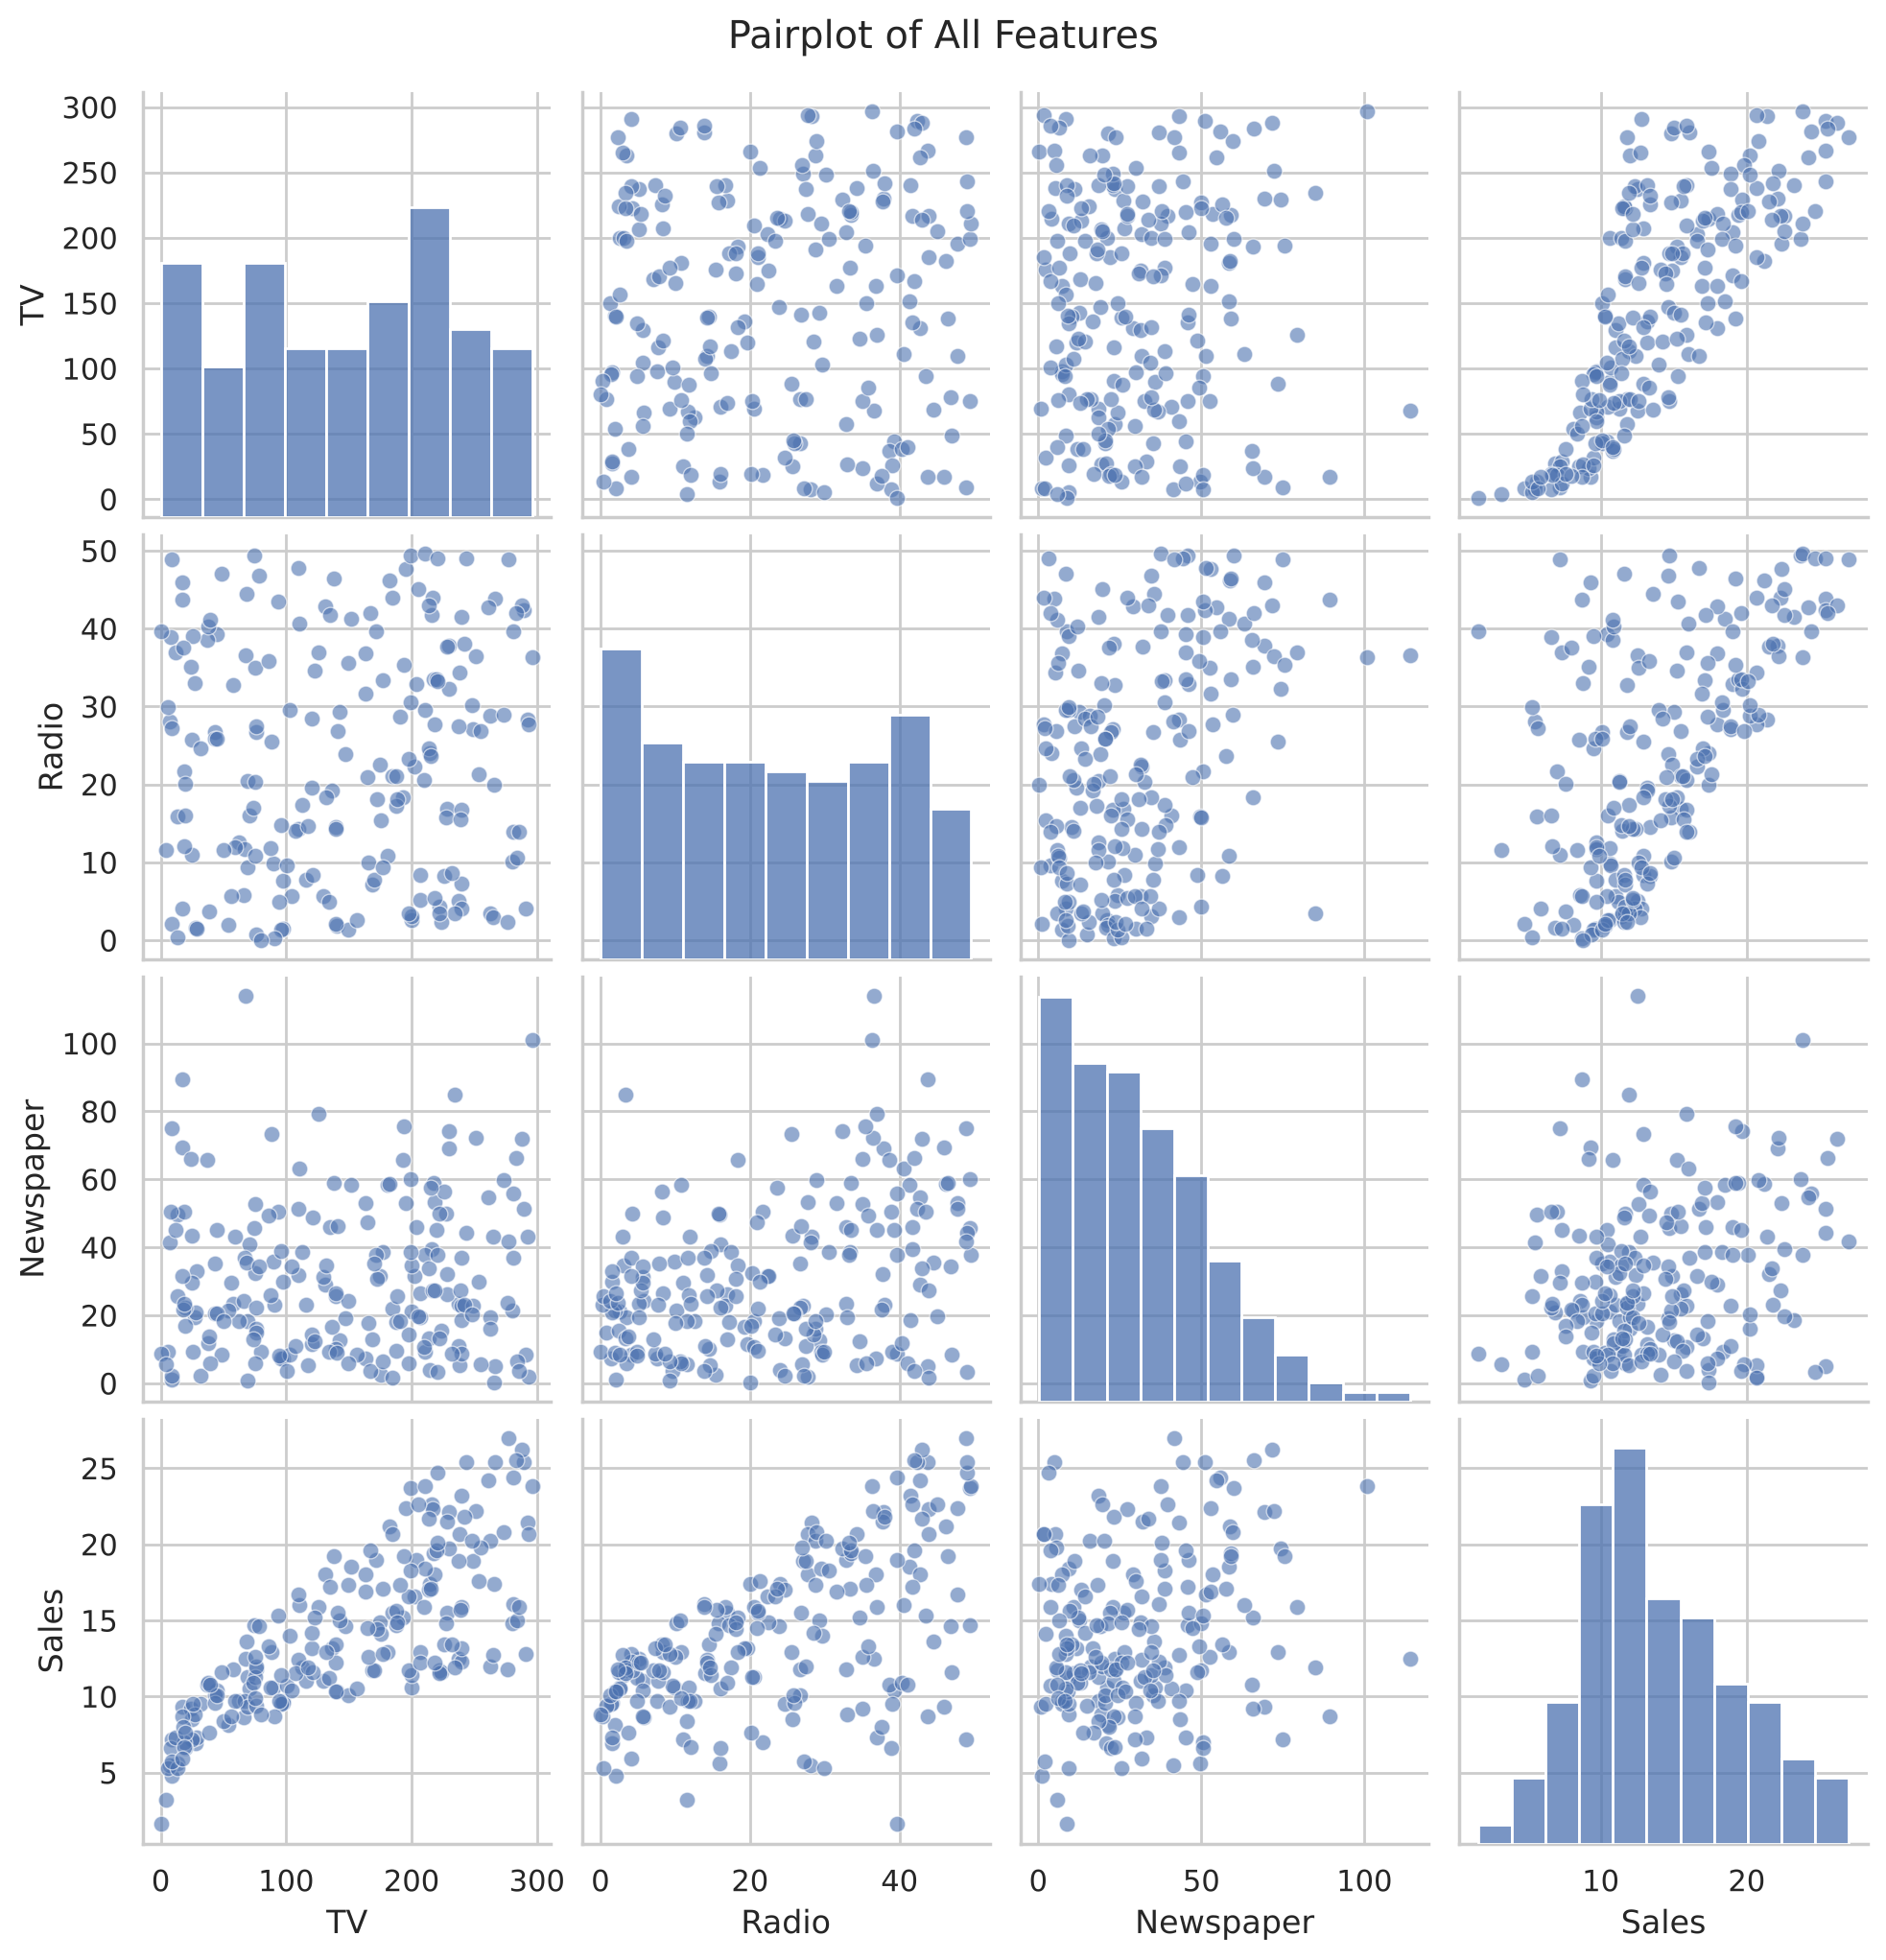

In [5]:
sns.pairplot(df, diag_kind="hist", plot_kws={"alpha": 0.6})
plt.suptitle("Pairplot of All Features", y=1.02); plt.show()

**Observation:** Sales rises clearly with TV spend and moderately with Radio spend. Newspaper shows a very weak relationship.

## 2. Sales vs Each Advertising Channel

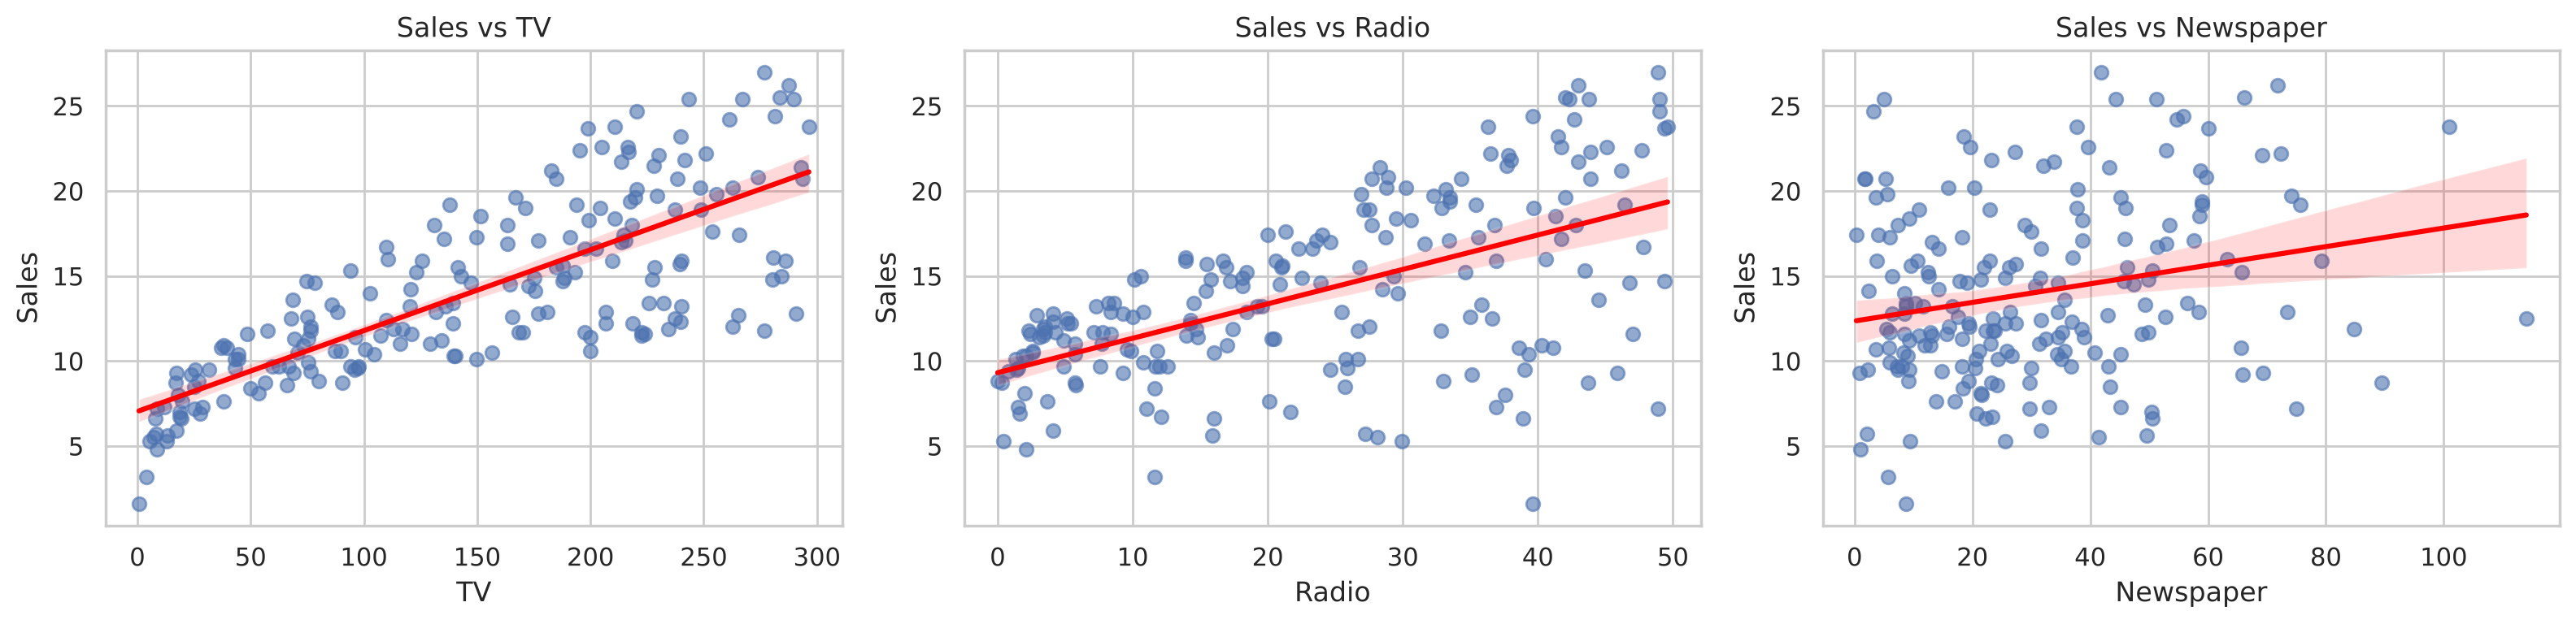

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["TV", "Radio", "Newspaper"]):
    sns.regplot(data=df, x=col, y="Sales", ax=ax, scatter_kws={"alpha": 0.6}, line_kws={"color": "red"})
    ax.set_title(f"Sales vs {col}")
plt.tight_layout(); plt.show()

## 3. Correlation Heatmap

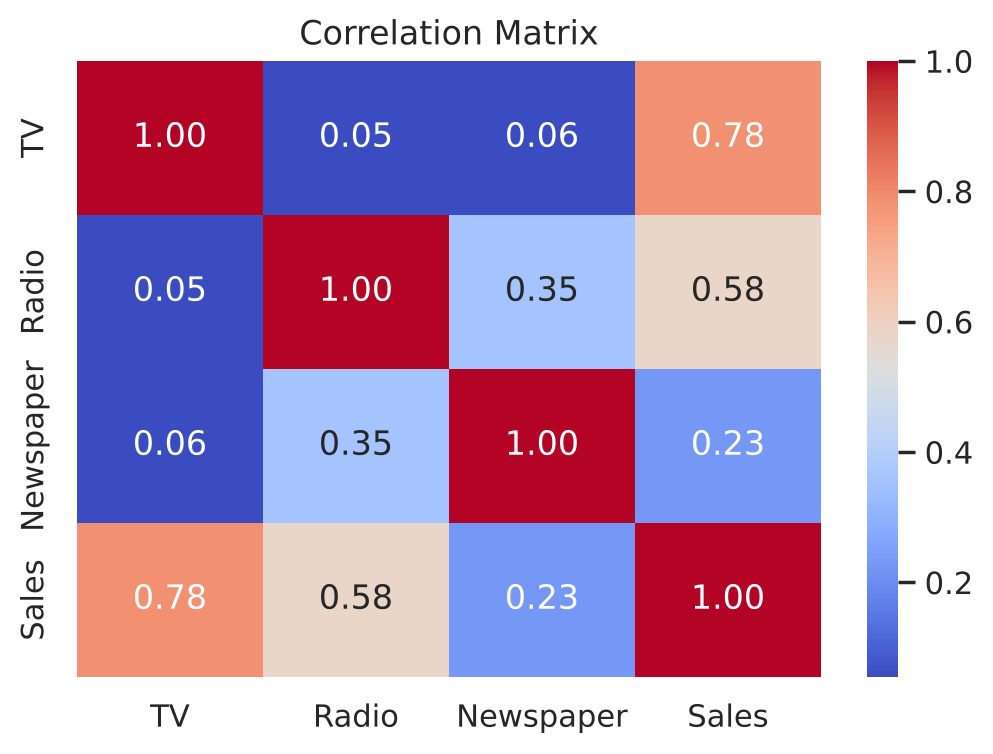

TV           0.782
Radio        0.576
Newspaper    0.228
Name: Sales, dtype: float64

In [7]:
plt.figure(figsize=(6, 4))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix"); plt.show()
df.corr()["Sales"].drop("Sales").sort_values(ascending=False).round(3)

## 4. Train / Test Split (80/20)

In [8]:
X = df[["TV", "Radio", "Newspaper"]]
y = df["Sales"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (160, 3)  Test: (40, 3)


## 5. Train Models
Linear Regression is the baseline. Polynomial Regression (degree 2) and Random Forest are the additional models.

In [9]:
models = {
    "Linear Regression (baseline)": LinearRegression(),
    "Polynomial Regression (deg 2)": make_pipeline(PolynomialFeatures(2, include_bias=False), LinearRegression()),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
}
preds = {}
for name, m in models.items():
    m.fit(X_train, y_train)
    preds[name] = m.predict(X_test)
print("Models trained.")

Models trained.


## 6. Evaluate: MAE, RMSE, R²

In [10]:
rows = []
for name, p in preds.items():
    rows.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, p),
        "RMSE": np.sqrt(mean_squared_error(y_test, p)),
        "R2": r2_score(y_test, p),
        "CV R2 (5-fold)": cross_val_score(models[name], X, y, cv=5, scoring="r2").mean(),
    })
results = pd.DataFrame(rows).set_index("Model").round(4).sort_values("R2", ascending=False)
results

,MAE,RMSE,R2,CV R2 (5-fold)
Model,,,,
Polynomial Regression (deg 2),0.5262,0.6426,0.9869,0.9843
Random Forest,0.6289,0.7577,0.9818,0.9758
Linear Regression (baseline),1.4608,1.7816,0.8994,0.8871


In [11]:
best_name = results["CV R2 (5-fold)"].idxmax()
print("Best model (by cross-validated R2):", best_name)

Best model (by cross-validated R2): Polynomial Regression (deg 2)


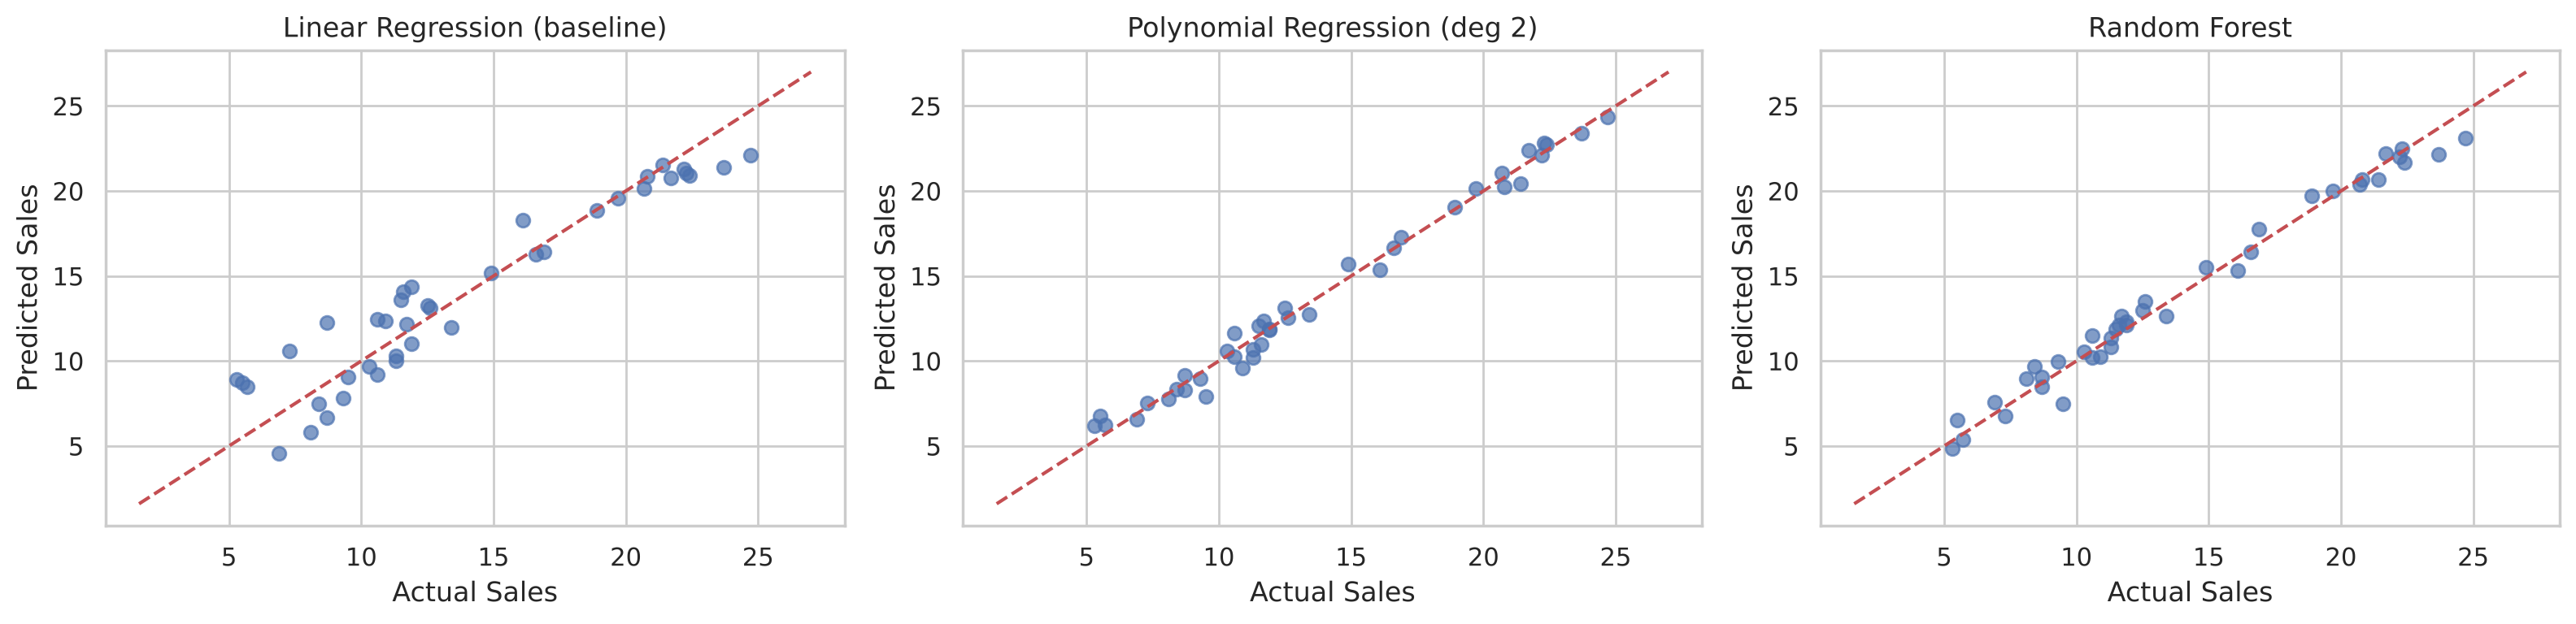

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, p) in zip(axes, preds.items()):
    ax.scatter(y_test, p, alpha=0.7)
    lims = [y.min(), y.max()]
    ax.plot(lims, lims, "r--")
    ax.set_title(name); ax.set_xlabel("Actual Sales"); ax.set_ylabel("Predicted Sales")
plt.tight_layout(); plt.show()

## 7. Residual Plot for the Best Model

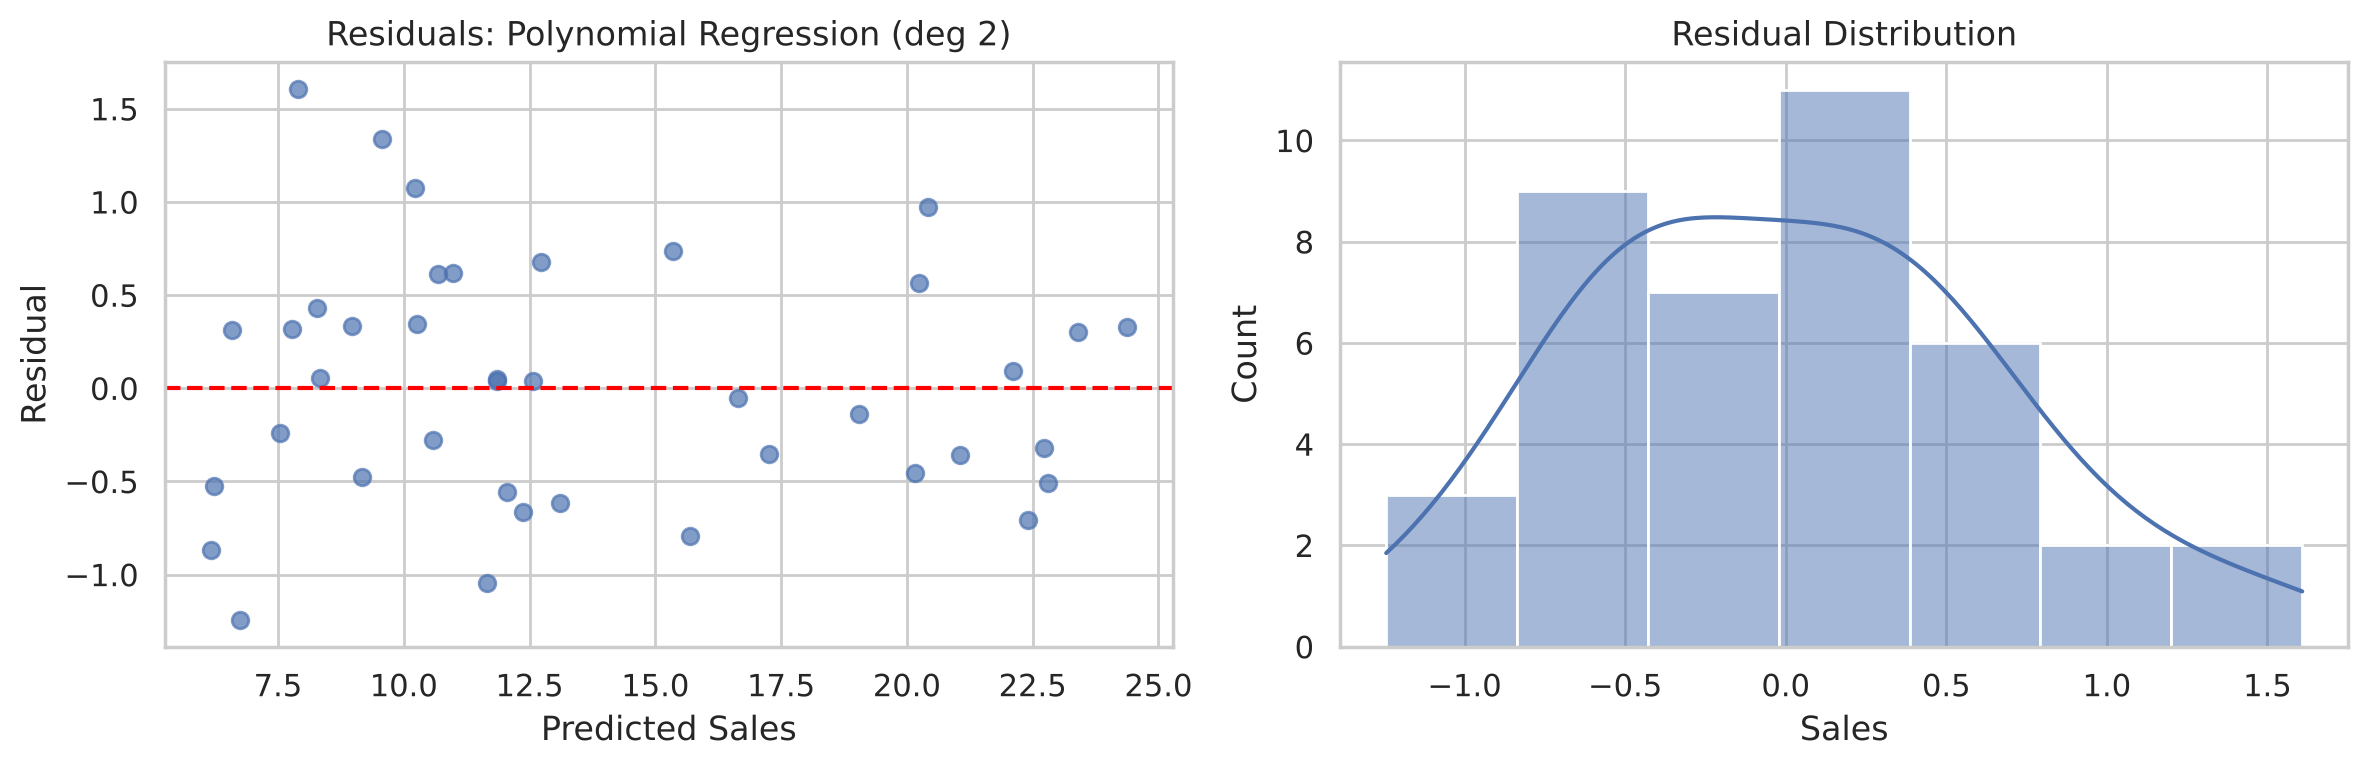

Mean residual: 0.0168


In [13]:
p = preds[best_name]
resid = y_test - p
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(p, resid, alpha=0.7)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("Predicted Sales"); axes[0].set_ylabel("Residual"); axes[0].set_title(f"Residuals: {best_name}")
sns.histplot(resid, kde=True, ax=axes[1])
axes[1].set_title("Residual Distribution")
plt.tight_layout(); plt.show()
print("Mean residual:", round(resid.mean(), 4))

## 8. Which Channel Has the Highest Impact?

Intercept: 2.979

Linear Regression coefficients (sales change per extra $1k spend):
TV           0.0447
Radio        0.1892
Newspaper    0.0028
dtype: float64

Standardised coefficients:
TV           3.929
Radio        2.799
Newspaper   -0.023
dtype: float64


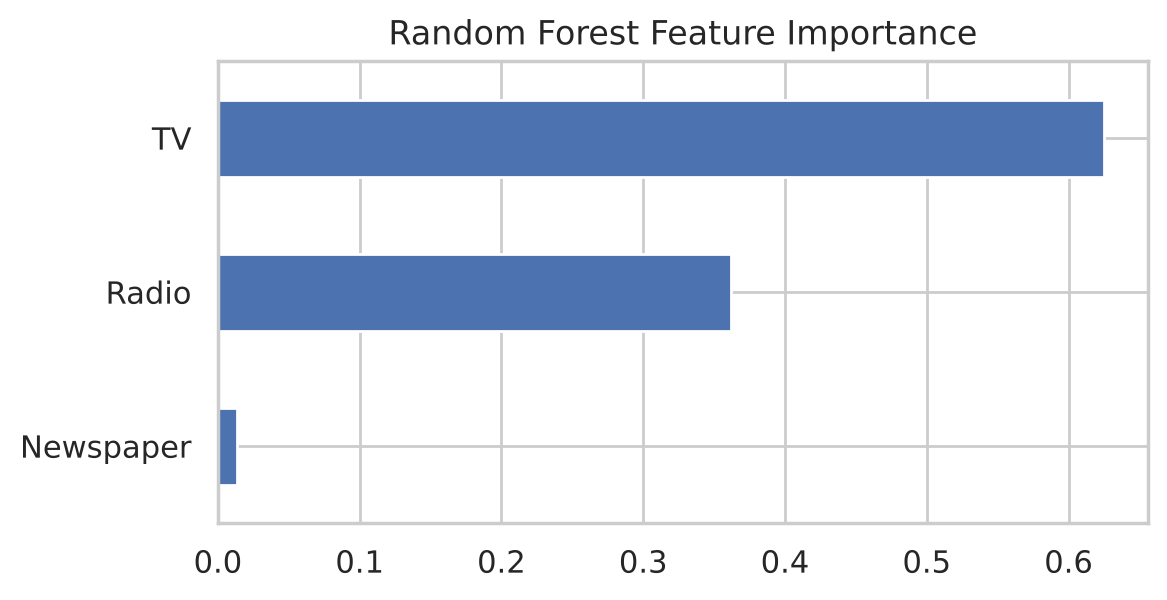

TV           0.625
Radio        0.362
Newspaper    0.013
dtype: float64


In [14]:
lr = models["Linear Regression (baseline)"]
coef = pd.Series(lr.coef_, index=X.columns)
print("Intercept:", round(lr.intercept_, 3))
print("\nLinear Regression coefficients (sales change per extra $1k spend):")
print(coef.round(4))

# Standardised coefficients allow a fair comparison since channels have different scales
Xs = (X - X.mean()) / X.std()
std_coef = pd.Series(LinearRegression().fit(Xs, y).coef_, index=X.columns)
print("\nStandardised coefficients:")
print(std_coef.round(3))

rf = models["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
imp.plot(kind="barh", title="Random Forest Feature Importance", figsize=(6, 3)); plt.show()
print(imp.round(3).sort_values(ascending=False))

## 9. Conclusion

**Model performance**
| Model | MAE | RMSE | R² (test) | R² (5-fold CV) |
|---|---|---|---|---|
| Polynomial Regression (deg 2) | 0.53 | 0.64 | 0.987 | 0.984 |
| Random Forest | 0.63 | 0.76 | 0.982 | 0.976 |
| Linear Regression (baseline) | 1.46 | 1.78 | 0.899 | 0.887 |

- **Best model: Polynomial Regression (degree 2).** It is the most accurate and also the simplest of the two strong models. The big jump over plain Linear Regression suggests the channels do not act independently. Polynomial terms include interactions such as TV × Radio, so the model can capture that the channels reinforce each other.
- **Residuals:** the mean residual of the best model is almost zero (~0.02), so predictions are not biased on average.

**Which channel matters most?**
- **TV** has the strongest correlation with Sales (0.78) and the largest standardised coefficient and Random Forest importance (~62%).
- **Radio** is second overall, but has the largest raw coefficient: about 0.19 extra units of sales per extra $1k spent, versus 0.045 for TV. Per dollar, Radio looks more effective, while TV drives more of the total variation because it is spent in much larger amounts.
- **Newspaper** has a near-zero effect once TV and Radio are accounted for (coefficient ≈ 0.003, importance ~1%). Its correlation with Sales (0.23) mostly comes from being correlated with Radio.

**Business takeaway:** prioritise TV and Radio budgets, and review whether Newspaper spend is worth it.

**Limitations:** only 200 rows and 3 features, and this is correlation, not proof of causation. Spend levels outside the observed range may not follow the same pattern.